In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.dummy import DummyRegressor

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.pipeline import make_pipeline

from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [6]:
DATA_PATH = "Downloads/lab_ticket_resolution.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


In [7]:
print("1. Dataset shape:")
print(df.shape)

print("\n2. Data types:")
print(df.dtypes)

print("\n3. Descriptive statistics:")
display(df.describe(include="all"))

print("\n4. Missing values:")
print(df.isna().sum())

print("\n5. First five rows:")
display(df.head())

1. Dataset shape:
(240, 6)

2. Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

3. Descriptive statistics:


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240,240.000000,240.000000,240.000000,240.000000,240.000000
unique,240,NaN,NaN,NaN,NaN,NaN
top,T0001,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,5.491667,54.820833,6.105417,0.233333,19.361125
std,NaN,2.979697,26.145017,3.391426,0.423836,10.035058
min,NaN,1.000000,1.000000,0.500000,0.000000,0.500000
25%,NaN,3.000000,33.000000,3.300000,0.000000,11.015000
50%,NaN,5.500000,54.000000,5.800000,0.000000,19.610000
75%,NaN,8.000000,74.000000,9.200000,0.000000,27.122500



4. Missing values:
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64

5. First five rows:


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


In [8]:
required_columns = [
    "ticket_id",
    "complexity_score",
    "lines_changed",
    "team_experience_years",
    "reopened",
    "resolution_hours"
]

print("Missing required columns:")
print(set(required_columns) - set(df.columns))

Missing required columns:
set()


In [9]:
X = df[
    ["complexity_score", "team_experience_years"]
].copy()

y = df["resolution_hours"].copy()

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nFeature columns:")
print(X.columns.tolist())

Features (X):


,complexity_score,team_experience_years
0,6,5.6
1,9,11.5
2,6,3.3
3,5,9.6
4,3,6.4



Target (y):


0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64


Feature columns:
['complexity_score', 'team_experience_years']


## Feature Selection and Data Leakage

The target variable is resolution_hours. The ticket_id column is excluded because it is a synthetic identifier rather than a predictive feature.

For this experiment, predictions are assumed to occur when a ticket is created. I selected complexity_score and team_experience_years, assuming both are available at that time.

I excluded lines_changed because the final number of lines changed may only be known after the fix. I also excluded reopened because reopening may occur after the initial prediction. These exclusions reduce the risk of data leakage.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (192, 2)
Testing features: (48, 2)
Training target: (192,)
Testing target: (48,)


In [11]:
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    print(f"\n{name}")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


results = []

In [12]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

results.append(
    evaluate_model(
        "Mean Baseline",
        y_test,
        baseline_predictions
    )
)


Mean Baseline
MAE:  9.1140
RMSE: 10.5977
R²:   -0.0210


In [13]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)


Linear Regression
MAE:  2.9060
RMSE: 3.5723
R²:   0.8840


In [14]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [15]:
poly_cv_results = {}

for degree in [2, 3]:

    poly_pipeline = make_pipeline(
        PolynomialFeatures(
            degree=degree,
            include_bias=False
        ),
        StandardScaler(),
        LinearRegression()
    )

    cv_scores = cross_val_score(
        poly_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    cv_mae = -cv_scores.mean()

    poly_cv_results[degree] = cv_mae

    print(
        f"Degree {degree} mean CV MAE: {cv_mae:.4f}"
    )

Degree 2 mean CV MAE: 3.1313
Degree 3 mean CV MAE: 3.1620


In [16]:
poly_models = {}
poly_predictions = {}

for degree in [2, 3]:

    model = make_pipeline(
        PolynomialFeatures(
            degree=degree,
            include_bias=False
        ),
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    poly_models[degree] = model
    poly_predictions[degree] = predictions

    results.append(
        evaluate_model(
            f"Polynomial Degree {degree}",
            y_test,
            predictions
        )
    )


Polynomial Degree 2
MAE:  3.0202
RMSE: 3.7409
R²:   0.8728

Polynomial Degree 3
MAE:  3.1398
RMSE: 3.9489
R²:   0.8582


In [17]:
ridge_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        Ridge()
    ),
    param_grid={
        "ridge__alpha": [0.01, 0.1, 1, 10, 100]
    },
    cv=cv,
    scoring="neg_mean_absolute_error"
)

ridge_search.fit(X_train, y_train)

ridge_model = ridge_search.best_estimator_

ridge_predictions = ridge_model.predict(X_test)

print("Selected Ridge alpha:")
print(ridge_search.best_params_["ridge__alpha"])

print("Ridge cross-validation MAE:")
print(-ridge_search.best_score_)

results.append(
    evaluate_model(
        "Ridge Regression",
        y_test,
        ridge_predictions
    )
)

Selected Ridge alpha:
0.01
Ridge cross-validation MAE:
3.168179510394688

Ridge Regression
MAE:  2.9060
RMSE: 3.5723
R²:   0.8840


In [18]:
lasso_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        Lasso(max_iter=10000)
    ),
    param_grid={
        "lasso__alpha": [0.001, 0.01, 0.1, 1, 10]
    },
    cv=cv,
    scoring="neg_mean_absolute_error"
)

lasso_search.fit(X_train, y_train)

lasso_model = lasso_search.best_estimator_

lasso_predictions = lasso_model.predict(X_test)

print("Selected Lasso alpha:")
print(lasso_search.best_params_["lasso__alpha"])

print("Lasso cross-validation MAE:")
print(-lasso_search.best_score_)

results.append(
    evaluate_model(
        "Lasso Regression",
        y_test,
        lasso_predictions
    )
)

Selected Lasso alpha:
0.001
Lasso cross-validation MAE:
3.1682419077442643

Lasso Regression
MAE:  2.9061
RMSE: 3.5723
R²:   0.8840


In [19]:
results_df = pd.DataFrame(results)

display(
    results_df
    .sort_values("MAE")
    .round(4)
    .reset_index(drop=True)
)

,Model,MAE,RMSE,R2
0,Ridge Regression,2.9060,3.5723,0.8840
1,Linear Regression,2.9060,3.5723,0.8840
2,Lasso Regression,2.9061,3.5723,0.8840
3,Polynomial Degree 2,3.0202,3.7409,0.8728
4,Polynomial Degree 3,3.1398,3.9489,0.8582
5,Mean Baseline,9.1140,10.5977,-0.0210


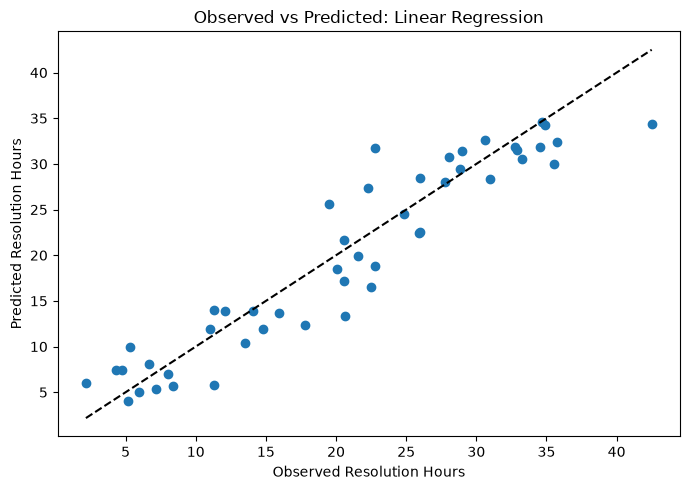

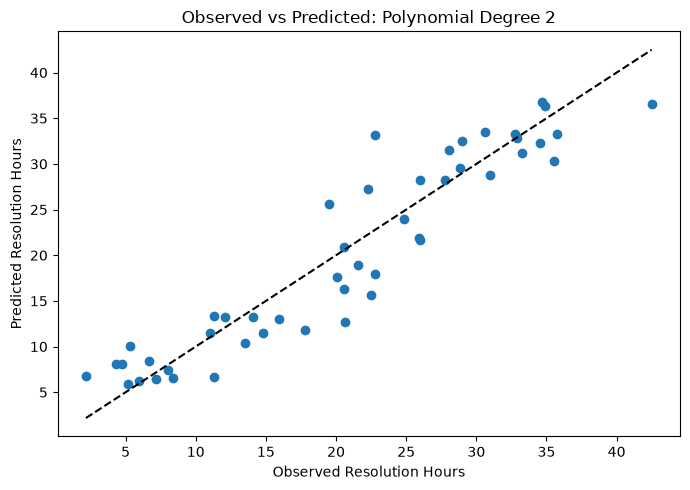

In [20]:
models_to_plot = {
    "Linear Regression": linear_predictions,
    "Polynomial Degree 2": poly_predictions[2]
}

for name, predictions in models_to_plot.items():

    plt.figure(figsize=(7, 5))

    plt.scatter(y_test, predictions)

    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())

    plt.plot(
        [low, high],
        [low, high],
        "k--"
    )

    plt.xlabel("Observed Resolution Hours")
    plt.ylabel("Predicted Resolution Hours")
    plt.title(f"Observed vs Predicted: {name}")

    plt.tight_layout()
    plt.show()

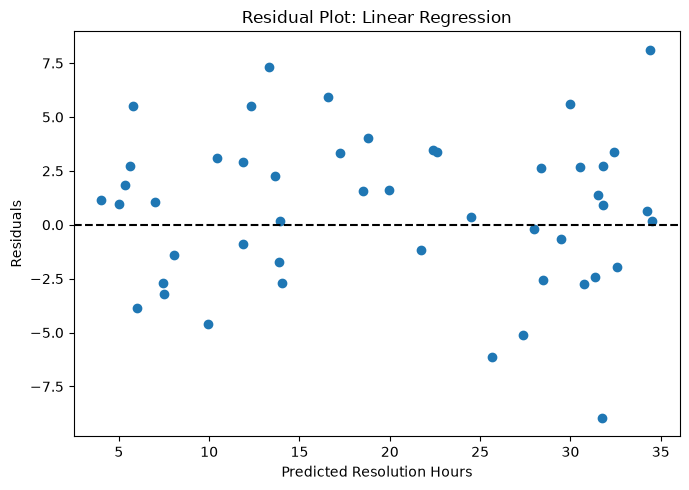

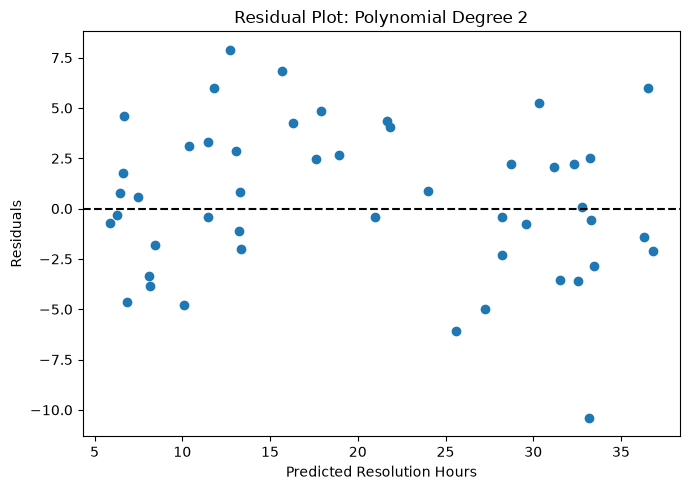

In [21]:
for name, predictions in models_to_plot.items():

    residuals = y_test.to_numpy() - predictions

    plt.figure(figsize=(7, 5))

    plt.scatter(predictions, residuals)
    plt.axhline(
        y=0,
        color="black",
        linestyle="--"
    )

    plt.xlabel("Predicted Resolution Hours")
    plt.ylabel("Residuals")
    plt.title(f"Residual Plot: {name}")

    plt.tight_layout()
    plt.show()

In [22]:
print("Polynomial cross-validation comparison")

for degree, mae in poly_cv_results.items():
    print(f"Degree {degree}: MAE = {mae:.4f}")

best_degree = min(
    poly_cv_results,
    key=poly_cv_results.get
)

print("\nPreferred polynomial degree:", best_degree)

Polynomial cross-validation comparison
Degree 2: MAE = 3.1313
Degree 3: MAE = 3.1620

Preferred polynomial degree: 2


## Analysis Questions

### 10. Why is the mean baseline useful even though it ignores all features?

The mean baseline provides a simple benchmark by predicting the average resolution time for every ticket. It helps determine whether more complex models provide useful predictive information.

### 11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?

I compared MAE and RMSE using the final test results. The model with the lowest MAE has the smallest average absolute prediction error. The model with the lowest RMSE performs best according to a metric that penalizes large errors more heavily. The winners may differ because the metrics measure errors differently.

### 12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?

I compared polynomial degrees 2 and 3 using five-fold cross-validation on the training set. The degree with the lower validation MAE performed better on average. I also compared test performance with linear regression to assess whether polynomial complexity improved generalization. A better training fit combined with worse validation performance may indicate overfitting.

### 13. How did regularization affect performance and coefficient magnitudes?

Ridge and Lasso penalize large coefficients. Ridge generally shrinks coefficients, while Lasso can set some coefficients to zero. I compared their test metrics with ordinary linear regression to determine whether regularization improved prediction performance.

### 14. Why is scaling included in the Ridge/Lasso pipeline?

Scaling puts features on comparable numerical scales. This is important because regularization penalizes coefficients, and differences in feature units can affect the penalty.

### 15. Identify one potential leakage issue and explain how you handled it.

The `lines_changed` feature may contain information that is unavailable when a ticket first arrives because the final number of changed lines is known only after work on the fix. The `reopened` feature may also describe a later event. I excluded both from the initial-prediction model and excluded `ticket_id` because it is an identifier.

### 16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams?

A random split may be unsuitable if the goal is to predict future tickets or if related tickets are highly dependent. A chronological split can better simulate predictions on future data. A group-based split can help prevent related customers or teams from appearing in both training and testing data.

### 17. What additional tests would you perform before deploying this model?

I would evaluate the model on real historical tickets, check for data leakage, investigate large prediction errors, assess performance across different teams and ticket types, and monitor performance over time. I would also confirm that the features are available when predictions are made.

## Final Recommendation

The objective of this lab was to estimate software support ticket resolution time using a synthetic dataset. I compared a mean baseline, Linear Regression, Polynomial Regression with degrees 2 and 3, Ridge Regression, and Lasso Regression.

The mean baseline achieved a test MAE of approximately 9.11 hours, while Linear Regression achieved a test MAE of approximately 2.91 hours and an RMSE of approximately 3.57 hours. Its R² was approximately 0.884, indicating that it explained about 88.4% of the variation in resolution time on the test set.

Based on these results, I recommend Linear Regression because it substantially improved prediction accuracy compared with the mean baseline while remaining relatively simple and interpretable. Polynomial Regression did not improve performance over Linear Regression in the reported test results. Ridge and Lasso Regression also did not provide a meaningful improvement over the ordinary linear model.

The dataset is synthetic, so these results do not establish that the model will perform equally well in a real organization. Before deployment, I would evaluate the model using real ticket data, investigate possible data leakage, examine residuals and large errors, assess performance across teams and ticket types, and test the model on newer tickets.